# Online Shoppers Buying Prediction
**Machine Learning - Assignment 2 (M.Tech AIML, BITS Pilani WILP)**

## a. Problem statement
A shopping website gets many visitors, but only a few of them actually buy something.
In this notebook we look at the details of each visit (pages seen, time spent, month, type of visitor, etc.) and try to **guess if the visit ended with a purchase or not** (`Revenue` = 1 means bought, 0 means did not buy).

We will train **5 different models** on the same data and compare them with 6 scores:
Accuracy, AUC, Precision, Recall, F1 and MCC.

## Step 0: Your details (fill this and keep it in the screenshot)

In [1]:
# Please write your own details here. This helps as proof when you take the BITS Virtual Lab screenshot.
my_name = "SUDHARSAN K"
my_id = "2026ak05405"

## Step 1: Bring in the tools we need

In [25]:
import os
import platform
import warnings
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_curve)

warnings.filterwarnings("ignore")

# A consistent, professional look for every chart in this notebook
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.0)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["figure.facecolor"] = "white"

# Show where this notebook is running (useful for the BITS Virtual Lab screenshot)
print("Name            :", my_name)
print("BITS ID         :", my_id)
print("Date and time   :", datetime.now().strftime("%d-%b-%Y %H:%M:%S"))
print("Computer name   :", platform.node())
print("Python version  :", platform.python_version())
print("Scikit-learn    :", sklearn.__version__)


Name            : SUDHARSAN K
BITS ID         : 2026ak05405
Date and time   : 31-Oct-2026 23:12:51
Computer name   : APAC-FW1FQV3
Python version  : 3.11.7
Scikit-learn    : 1.9.1


## Step 2: Load the dataset
**Dataset:** Online Shoppers Purchasing Intention Dataset (UCI Machine Learning Repository).
Keep the file `online_shoppers_intention.csv` in the same folder as this notebook.

In [3]:
data_file_name = "online_shoppers_intention.csv"
shopping_data = pd.read_csv(data_file_name)

print("Rows and columns:", shopping_data.shape)
shopping_data.head()

Rows and columns: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## Step 3: Look at the data (simple checks)

In [4]:
# Column names, data types and how many values are filled
shopping_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [5]:
# Basic numbers (smallest, biggest, average) for each number column
shopping_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [6]:
# Are there any empty (missing) values?
print("Total empty values:", shopping_data.isnull().sum().sum())

# Are there any rows that are repeated?
print("Repeated rows     :", shopping_data.duplicated().sum())

Total empty values: 0
Repeated rows     : 125


Revenue
False    10422
True      1908
Name: count, dtype: int64

Percent of visits that bought something: 15.47 %


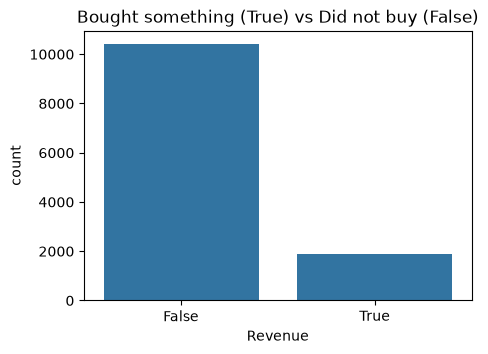

In [7]:
# How many visits ended with a purchase and how many did not?
buy_counts = shopping_data["Revenue"].value_counts()
print(buy_counts)
print()
print("Percent of visits that bought something:",
      round(buy_counts[True] / len(shopping_data) * 100, 2), "%")

plt.figure(figsize=(5, 3.5))
sns.countplot(data=shopping_data, x="Revenue")
plt.title("Bought something (True) vs Did not buy (False)")
plt.show()

**What we see:** The data is **not balanced**. Only about 15 out of every 100 visits end in a purchase.
So a model can look good on Accuracy just by saying "will not buy" every time. This is why we also check Precision, Recall, F1 and MCC.

## Step 4: Clean the data

In [8]:
# 1) Remove the repeated rows
rows_before = len(shopping_data)
shopping_data = shopping_data.drop_duplicates().reset_index(drop=True)
print("Rows removed:", rows_before - len(shopping_data))
print("Rows left   :", len(shopping_data))

# 2) Change True/False columns into 1/0 so that the models can read them
shopping_data["Weekend"] = shopping_data["Weekend"].astype(int)
shopping_data["Revenue"] = shopping_data["Revenue"].astype(int)

Rows removed: 125
Rows left   : 12205


## Step 5: Decide which column is the answer and which columns are the clues
- **Answer (target):** `Revenue` (1 = bought, 0 = did not buy)
- **Clues (features):** the other 17 columns
- Two clue columns are words (`Month`, `VisitorType`). Models cannot read words, so we turn them into 0/1 columns (one-hot).
- The other clue columns are numbers. We put them on the same scale so that big numbers (like time in seconds) do not overpower small numbers.

In [9]:
answer_column = "Revenue"
word_columns = ["Month", "VisitorType"]
number_columns = [col for col in shopping_data.columns
                  if col not in word_columns + [answer_column]]

print("Number of clue columns:", len(word_columns) + len(number_columns))
print("Word columns          :", word_columns)
print("Number columns        :", number_columns)

Number of clue columns: 17
Word columns          : ['Month', 'VisitorType']
Number columns        : ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']


## Step 5b: A deeper look at the data (Exploratory Data Analysis)
Before training any model, we look at **how the clues relate to the answer** (`Revenue`). This tells us which signals the models are likely to rely on and gives the "observations" needed for the README.

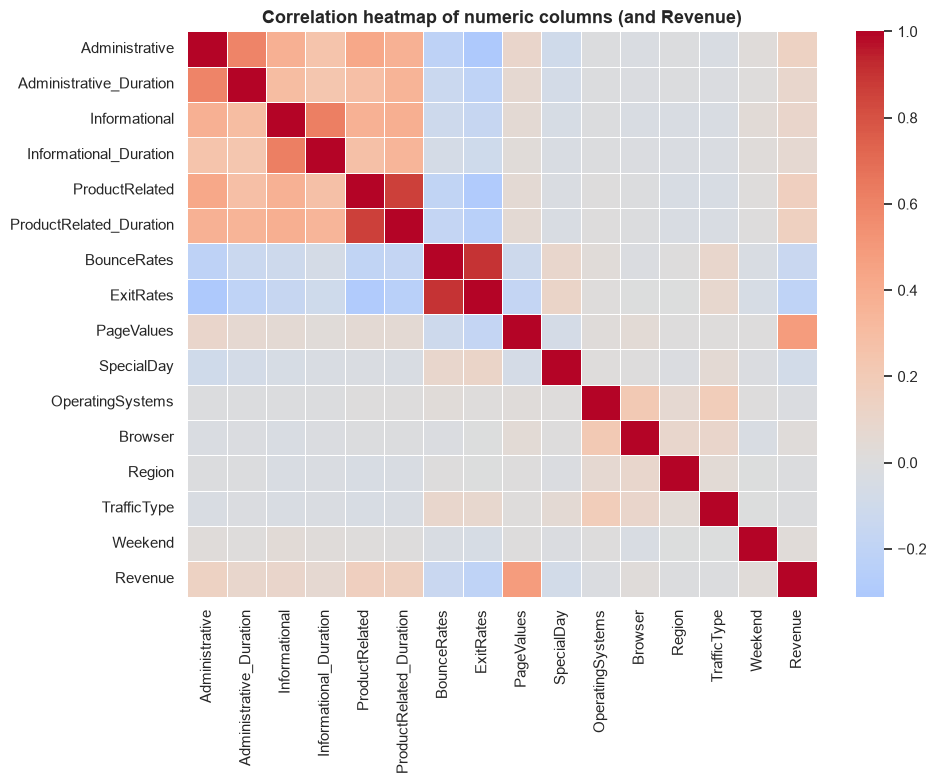

Columns most correlated with Revenue:
PageValues                 0.492
ExitRates                 -0.204
ProductRelated             0.156
ProductRelated_Duration    0.150
BounceRates               -0.145
Administrative             0.136
Informational              0.094
Administrative_Duration    0.092
SpecialDay                -0.084
Informational_Duration     0.069
Weekend                    0.028
Browser                    0.024
OperatingSystems          -0.015
Region                    -0.013
TrafficType               -0.006
Name: Revenue, dtype: float64


In [26]:
plt.figure(figsize=(10, 8))
correlation_matrix = shopping_data[number_columns + [answer_column]].corr()
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", center=0, linewidths=0.4)
plt.title("Correlation heatmap of numeric columns (and Revenue)")
plt.tight_layout()
plt.show()

print("Columns most correlated with Revenue:")
print(correlation_matrix[answer_column].drop(answer_column).sort_values(key=abs, ascending=False).round(3))


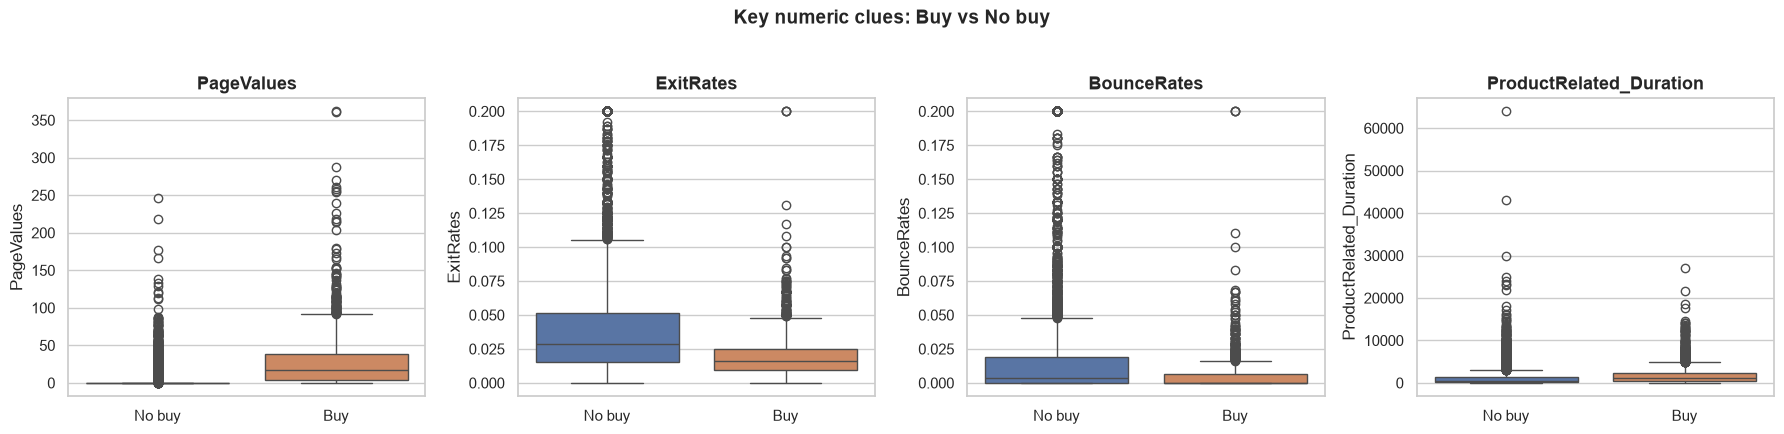

In [27]:
key_features = ["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"]

fig, boxes = plt.subplots(1, 4, figsize=(18, 4.2))
for box, feature in zip(boxes, key_features):
    sns.boxplot(data=shopping_data, x=answer_column, y=feature, hue=answer_column,
                palette=["#4C72B0", "#DD8452"], legend=False, ax=box)
    box.set_xticks([0, 1])
    box.set_xticklabels(["No buy", "Buy"])
    box.set_xlabel("")
    box.set_title(feature)

plt.suptitle("Key numeric clues: Buy vs No buy", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


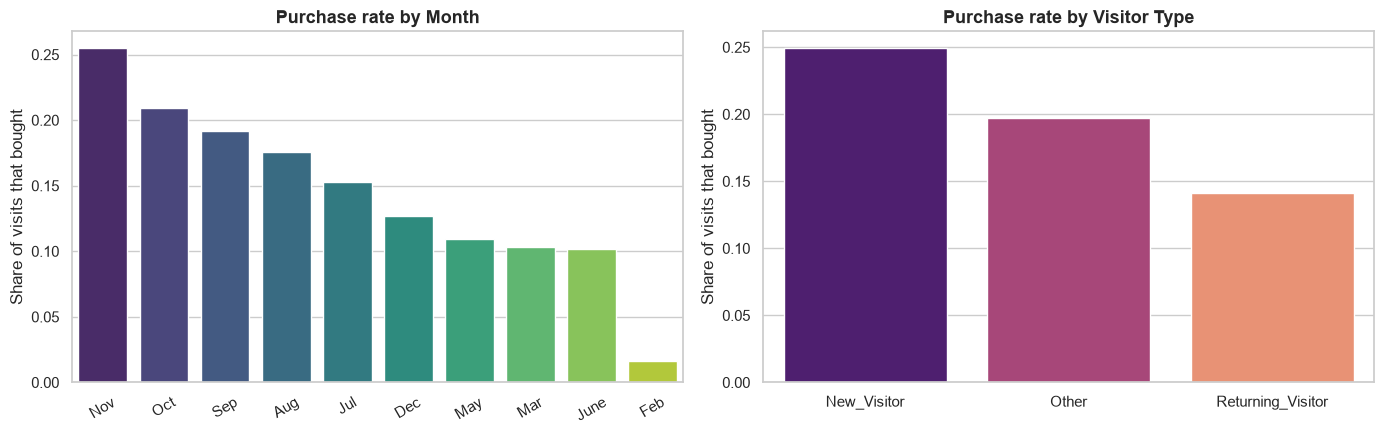

In [28]:
fig, (axis_month, axis_visitor) = plt.subplots(1, 2, figsize=(14, 4.5))

month_rate = shopping_data.groupby("Month")[answer_column].mean().sort_values(ascending=False)
sns.barplot(x=month_rate.index, y=month_rate.values, hue=month_rate.index,
            palette="viridis", legend=False, ax=axis_month)
axis_month.set_title("Purchase rate by Month")
axis_month.set_ylabel("Share of visits that bought")
axis_month.set_xlabel("")
axis_month.tick_params(axis="x", rotation=30)

visitor_rate = shopping_data.groupby("VisitorType")[answer_column].mean().sort_values(ascending=False)
sns.barplot(x=visitor_rate.index, y=visitor_rate.values, hue=visitor_rate.index,
            palette="magma", legend=False, ax=axis_visitor)
axis_visitor.set_title("Purchase rate by Visitor Type")
axis_visitor.set_ylabel("Share of visits that bought")
axis_visitor.set_xlabel("")

plt.tight_layout()
plt.show()


In [29]:
outlier_summary = []
for col in number_columns:
    q1, q3 = shopping_data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_count = ((shopping_data[col] < lower) | (shopping_data[col] > upper)).sum()
    outlier_summary.append({
        "Column": col,
        "Outliers (IQR rule)": outlier_count,
        "% of rows": round(outlier_count / len(shopping_data) * 100, 2),
    })

outlier_table = pd.DataFrame(outlier_summary).sort_values("% of rows", ascending=False).reset_index(drop=True)
outlier_table.head(8)


,Column,Outliers (IQR rule),% of rows
0,Browser,4322,35.41
1,Weekend,2859,23.42
2,PageValues,2730,22.37
3,Informational,2631,21.56
4,Informational_Duration,2405,19.71
5,TrafficType,2084,17.07
6,BounceRates,1428,11.70
7,ExitRates,1325,10.86


**What we see:** `PageValues` has by far the strongest link with `Revenue` (correlation 0.49) — visits that reach high-value pages are much more likely to end in a purchase. `ExitRates` and `BounceRates` move the other way: visits that leave quickly rarely buy, which the boxplots confirm (buyers have lower exit/bounce rates and higher `PageValues`). November has the highest purchase rate (holiday shopping season) and new visitors convert more often than returning visitors. The IQR rule flags a large "outlier" share in a few columns, but most of that comes from naturally skewed/near-binary columns (`Browser`, `Weekend`, `TrafficType` codes) rather than data errors; the genuinely interesting outliers are the high `PageValues` and long duration sessions, which are kept as-is because they represent real high-intent visits — exactly the pattern we want the models to learn. Scaling with `StandardScaler` keeps these large values from unfairly dominating distance/gradient-based models (KNN, SVM, Logistic Regression).

## Step 6: Split into training data and test data
- 80% of the rows are used to **teach** the models (training data).
- 20% of the rows are kept aside to **check** the models (test data). The models never see these rows while learning.
- `stratify` keeps the same buy / not-buy ratio in both parts.

In [10]:
clues = shopping_data.drop(columns=[answer_column])
answers = shopping_data[answer_column]

clues_train, clues_test, answers_train, answers_test = train_test_split(
    clues, answers, test_size=0.2, random_state=42, stratify=answers)

print("Training rows:", len(clues_train))
print("Test rows    :", len(clues_test))

Training rows: 9764
Test rows    : 2441


## Step 7: Save the test data as `test_data.csv`
This file goes to GitHub and is uploaded in the Streamlit app. It has all 17 clue columns **and** the `Revenue` column, as the assignment asks.

In [11]:
test_data = clues_test.copy()
test_data[answer_column] = answers_test.values
test_data.to_csv("test_data.csv", index=False)

print("Saved test_data.csv with shape:", test_data.shape)
test_data.head()

Saved test_data.csv with shape: (2441, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
11640,0,0.000000,0,0.0,12,482.500000,0.02,0.040000,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,0,0
6936,2,287.200000,0,0.0,16,473.283333,0.00,0.002222,0.0,0.0,Oct,2,2,1,2,New_Visitor,1,0
7194,2,187.900000,4,100.1,29,2107.033333,0.00,0.024242,0.0,0.0,Oct,1,1,3,1,Returning_Visitor,0,0
11263,7,280.266667,0,0.0,11,329.683333,0.00,0.023077,0.0,0.0,Dec,2,2,7,2,Returning_Visitor,0,0
4728,0,0.000000,0,0.0,5,0.000000,0.20,0.200000,0.0,0.0,May,3,2,5,6,Returning_Visitor,0,0


## Step 8: Build the 5 models
Each model is packed together with the cleaning step (scaling + one-hot) in one **pipeline**.
This way, when the Streamlit app loads a saved model, the cleaning is done automatically and nothing is missed.

In [12]:
def build_pipeline(classifier):
    # Cleaning step: scale the number columns, turn the word columns into 0/1 columns
    cleaning_step = ColumnTransformer(
        transformers=[
            ("scale_numbers", StandardScaler(), number_columns),
            ("words_to_zero_one", OneHotEncoder(handle_unknown="ignore"), word_columns),
        ],
        sparse_threshold=0,   # keep the output as a normal table (Naive Bayes needs this)
    )
    return Pipeline([("cleaning", cleaning_step), ("classifier", classifier)])


all_models = {
    "Logistic Regression":    build_pipeline(LogisticRegression(max_iter=1000, random_state=42)),
    "Decision Tree":          build_pipeline(DecisionTreeClassifier(max_depth=6, random_state=42)),
    "KNN":                    build_pipeline(KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes":            build_pipeline(GaussianNB()),
    "Support Vector Machine": build_pipeline(SVC(kernel="rbf", probability=True, random_state=42)),
}

print("Models ready:", list(all_models.keys()))

Models ready: ['Logistic Regression', 'Decision Tree', 'KNN', 'Naive Bayes', 'Support Vector Machine']


## Step 9: Teach each model and check it on the test data
Scores we calculate (all for the class "bought = 1"):
| Score | Simple meaning |
|---|---|
| Accuracy | Out of all guesses, how many were right |
| AUC | How well the model separates buyers from non-buyers (1.0 is perfect, 0.5 is a coin toss) |
| Precision | When the model says "will buy", how often is it right |
| Recall | Out of all real buyers, how many did the model catch |
| F1 | One number that balances Precision and Recall |
| MCC | One fair number for imbalanced data (1 is perfect, 0 is random guessing) |

In [13]:
def get_all_scores(real_answers, guessed_answers, guessed_chances):
    return {
        "Accuracy":  accuracy_score(real_answers, guessed_answers),
        "AUC":       roc_auc_score(real_answers, guessed_chances),
        "Precision": precision_score(real_answers, guessed_answers, zero_division=0),
        "Recall":    recall_score(real_answers, guessed_answers, zero_division=0),
        "F1":        f1_score(real_answers, guessed_answers, zero_division=0),
        "MCC":       matthews_corrcoef(real_answers, guessed_answers),
    }


scores_of_models = {}      # keeps the 6 scores of every model
guesses_of_models = {}     # keeps the yes/no guesses of every model
chances_of_models = {}     # keeps the "chance of buying" of every model

for model_name, model in all_models.items():
    print("Teaching:", model_name, "...")
    model.fit(clues_train, answers_train)

    guessed_answers = model.predict(clues_test)
    guessed_chances = model.predict_proba(clues_test)[:, 1]

    guesses_of_models[model_name] = guessed_answers
    chances_of_models[model_name] = guessed_chances
    scores_of_models[model_name] = get_all_scores(answers_test, guessed_answers, guessed_chances)

print("Done.")

Teaching: Logistic Regression ...
Teaching: Decision Tree ...
Teaching: KNN ...
Teaching: Naive Bayes ...
Teaching: Support Vector Machine ...
Done.


## Step 10: Comparison table of all 5 models

In [14]:
comparison_table = pd.DataFrame(scores_of_models).T.round(4)
comparison_table.index.name = "ML Model Name"
comparison_table

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8894,0.9022,0.7718,0.4162,0.5408,0.5142
Decision Tree,0.8980,0.9122,0.6997,0.6099,0.6517,0.5942
KNN,0.8800,0.8208,0.7051,0.4005,0.5109,0.4716
Naive Bayes,0.7108,0.8268,0.3284,0.8115,0.4676,0.3757
Support Vector Machine,0.8943,0.8799,0.7403,0.5000,0.5969,0.5524


In [15]:
# Same table in README format (copy this and paste it into README.md)
table_lines = ["| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |",
               "|---|---|---|---|---|---|---|"]
for model_name, row in comparison_table.iterrows():
    table_lines.append(f"| {model_name} | {row['Accuracy']:.4f} | {row['AUC']:.4f} | "
                       f"{row['Precision']:.4f} | {row['Recall']:.4f} | {row['F1']:.4f} | {row['MCC']:.4f} |")
print("\n".join(table_lines))

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.8894 | 0.9022 | 0.7718 | 0.4162 | 0.5408 | 0.5142 |
| Decision Tree | 0.8980 | 0.9122 | 0.6997 | 0.6099 | 0.6517 | 0.5942 |
| KNN | 0.8800 | 0.8208 | 0.7051 | 0.4005 | 0.5109 | 0.4716 |
| Naive Bayes | 0.7108 | 0.8268 | 0.3284 | 0.8115 | 0.4676 | 0.3757 |
| Support Vector Machine | 0.8943 | 0.8799 | 0.7403 | 0.5000 | 0.5969 | 0.5524 |


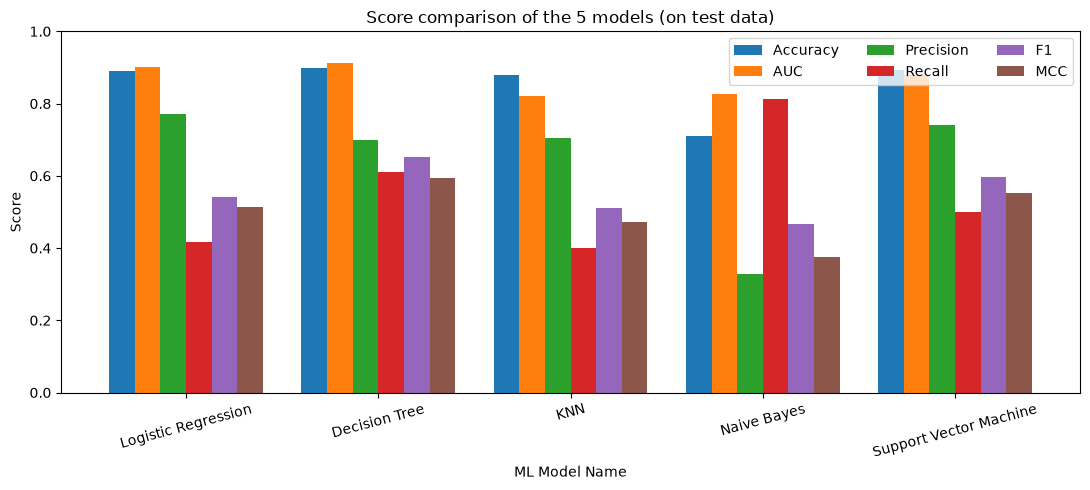

In [16]:
# A picture to compare the models side by side
comparison_table.plot(kind="bar", figsize=(11, 5), width=0.8)
plt.title("Score comparison of the 5 models (on test data)")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc="upper right", ncol=3)
plt.tight_layout()
plt.show()

## Step 11: Confusion matrix of every model

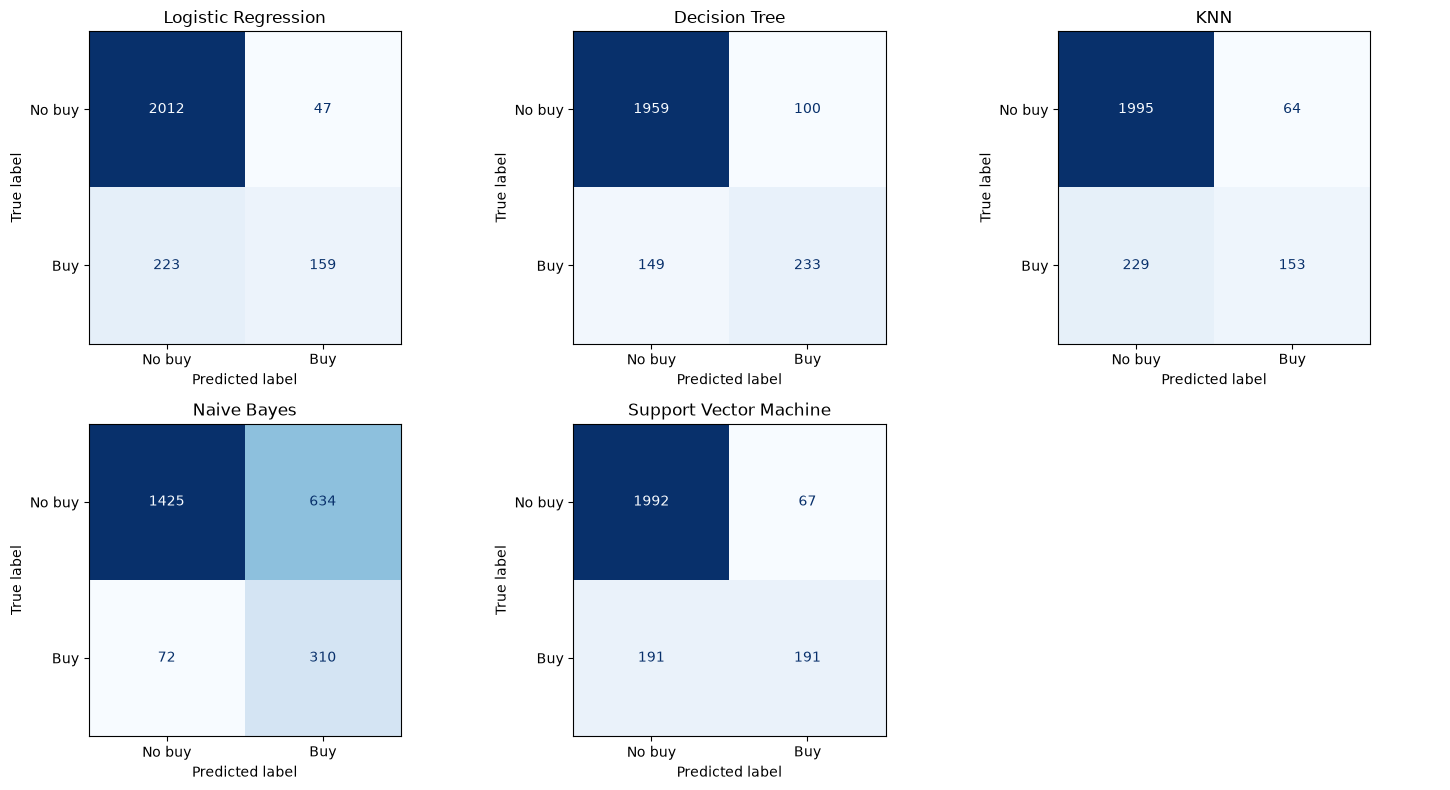

In [17]:
fig, boxes = plt.subplots(2, 3, figsize=(15, 8))
boxes = boxes.flatten()

for box, model_name in zip(boxes, all_models.keys()):
    ConfusionMatrixDisplay.from_predictions(
        answers_test, guesses_of_models[model_name], ax=box,
        display_labels=["No buy", "Buy"], cmap="Blues", colorbar=False)
    box.set_title(model_name)

boxes[-1].axis("off")   # the 6th box is empty
plt.tight_layout()
plt.show()

## Step 12: Classification report of every model

In [18]:
for model_name in all_models.keys():
    print("=" * 60)
    print(model_name)
    print("=" * 60)
    print(classification_report(answers_test, guesses_of_models[model_name],
                                target_names=["No buy (0)", "Buy (1)"], zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

  No buy (0)       0.90      0.98      0.94      2059
     Buy (1)       0.77      0.42      0.54       382

    accuracy                           0.89      2441
   macro avg       0.84      0.70      0.74      2441
weighted avg       0.88      0.89      0.88      2441

Decision Tree
              precision    recall  f1-score   support

  No buy (0)       0.93      0.95      0.94      2059
     Buy (1)       0.70      0.61      0.65       382

    accuracy                           0.90      2441
   macro avg       0.81      0.78      0.80      2441
weighted avg       0.89      0.90      0.90      2441

KNN
              precision    recall  f1-score   support

  No buy (0)       0.90      0.97      0.93      2059
     Buy (1)       0.71      0.40      0.51       382

    accuracy                           0.88      2441
   macro avg       0.80      0.68      0.72      2441
weighted avg       0.87      0.88   

## Step 13: ROC curve (how well each model separates buyers from non-buyers)

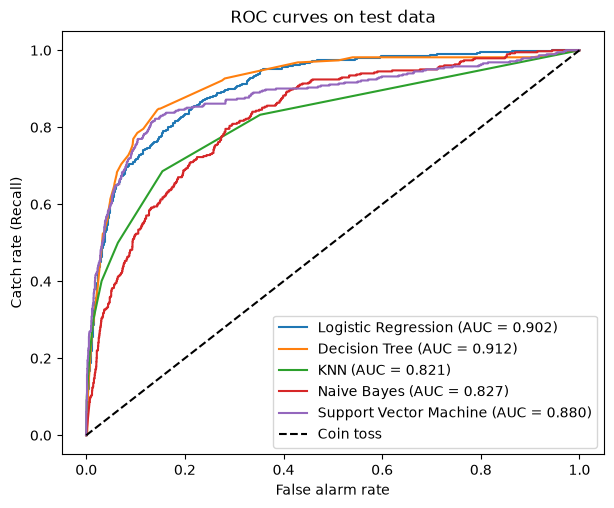

In [19]:
plt.figure(figsize=(7, 5.5))
for model_name in all_models.keys():
    false_alarm_rate, catch_rate, _ = roc_curve(answers_test, chances_of_models[model_name])
    plt.plot(false_alarm_rate, catch_rate,
             label=f"{model_name} (AUC = {scores_of_models[model_name]['AUC']:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Coin toss")
plt.xlabel("False alarm rate")
plt.ylabel("Catch rate (Recall)")
plt.title("ROC curves on test data")
plt.legend(loc="lower right")
plt.show()

## Step 14: Which model is the winner?

In [20]:
# We pick the winner using MCC, because MCC is the fairest score when the data is not balanced.
winner_name = comparison_table["MCC"].idxmax()
print("Winner by MCC      :", winner_name)
print("Winner by F1       :", comparison_table["F1"].idxmax())
print("Winner by AUC      :", comparison_table["AUC"].idxmax())
print("Winner by Accuracy :", comparison_table["Accuracy"].idxmax())
print()
print("Best model scores:")
print(comparison_table.loc[winner_name])

Winner by MCC      : Decision Tree
Winner by F1       : Decision Tree
Winner by AUC      : Decision Tree
Winner by Accuracy : Decision Tree

Best model scores:
Accuracy     0.8980
AUC          0.9122
Precision    0.6997
Recall       0.6099
F1           0.6517
MCC          0.5942
Name: Decision Tree, dtype: float64


## Step 14b: What does the best model look at? (Feature importance)
This shows which clues the winning model relies on the most, confirming the patterns we saw earlier in the EDA.

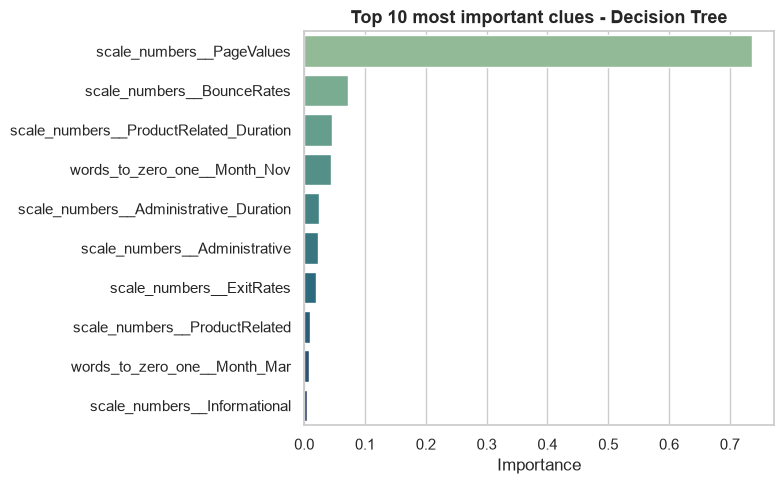

In [30]:
best_pipeline = all_models[winner_name]
feature_names = best_pipeline.named_steps["cleaning"].get_feature_names_out()
classifier_step = best_pipeline.named_steps["classifier"]

if hasattr(classifier_step, "feature_importances_"):
    importance_values = classifier_step.feature_importances_
elif hasattr(classifier_step, "coef_"):
    importance_values = np.abs(classifier_step.coef_).ravel()
else:
    importance_values = None

if importance_values is not None:
    importance_table = pd.Series(importance_values, index=feature_names).sort_values(ascending=False).head(10)
    plt.figure(figsize=(8, 5))
    sns.barplot(x=importance_table.values, y=importance_table.index, hue=importance_table.index,
                palette="crest", legend=False)
    plt.title(f"Top 10 most important clues - {winner_name}")
    plt.xlabel("Importance")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
else:
    print(f"{winner_name} does not expose a simple feature importance/coefficient.")


## Step 15: Save the trained models in the `model/` folder

In [21]:
os.makedirs("model", exist_ok=True)

model_file_names = {
    "Logistic Regression":    "model/logistic_regression.pkl",
    "Decision Tree":          "model/decision_tree.pkl",
    "KNN":                    "model/knn.pkl",
    "Naive Bayes":            "model/naive_bayes.pkl",
    "Support Vector Machine": "model/svm.pkl",
}

for model_name, file_path in model_file_names.items():
    joblib.dump(all_models[model_name], file_path)
    size_in_mb = os.path.getsize(file_path) / (1024 * 1024)
    print(f"Saved {file_path}  ({size_in_mb:.2f} MB)")

Saved model/logistic_regression.pkl  (0.00 MB)
Saved model/decision_tree.pkl  (0.01 MB)
Saved model/knn.pkl  (2.16 MB)
Saved model/naive_bayes.pkl  (0.01 MB)
Saved model/svm.pkl  (0.64 MB)


## Step 16: Double check - load the saved models and test them on `test_data.csv`
This is exactly what the Streamlit app does (load the saved model and score it, no re-training).
The scores must match the table above.

In [22]:
check_data = pd.read_csv("test_data.csv")
check_clues = check_data.drop(columns=[answer_column])
check_answers = check_data[answer_column]

for model_name, file_path in model_file_names.items():
    loaded_model = joblib.load(file_path)
    loaded_guesses = loaded_model.predict(check_clues)
    loaded_accuracy = accuracy_score(check_answers, loaded_guesses)
    same_as_before = np.isclose(loaded_accuracy, scores_of_models[model_name]["Accuracy"])
    print(f"{model_name:25s} accuracy = {loaded_accuracy:.4f}   matches table: {same_as_before}")

Logistic Regression       accuracy = 0.8894   matches table: True
Decision Tree             accuracy = 0.8980   matches table: True
KNN                       accuracy = 0.8800   matches table: True
Naive Bayes               accuracy = 0.7108   matches table: True
Support Vector Machine    accuracy = 0.8943   matches table: True


## Step 17: Create `requirements.txt` (the same library versions as this lab)
Missing or wrong libraries are the number one reason for a failed deployment. This cell writes the file for you.

In [23]:
from importlib.metadata import version

# Only these libraries are really needed by the app. Streamlit gets no fixed number on purpose.
needed_libraries = ["scikit-learn", "numpy", "pandas", "matplotlib", "seaborn", "joblib"]

lines = ["streamlit"]
for library in needed_libraries:
    lines.append(f"{library}=={version(library)}")

with open("requirements.txt", "w") as file:
    file.write("\n".join(lines) + "\n")

print(open("requirements.txt").read())

streamlit
scikit-learn==1.9.1
numpy==2.4.6
pandas==3.1.0
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0



## Final: Files this notebook has created
Upload all of these to your GitHub repository:
`test_data.csv`, `requirements.txt`, and the whole `model/` folder.
Also keep `app.py`, `README.md`, this notebook and `online_shoppers_intention.csv` in the repository.

In [24]:
for item in ["test_data.csv", "requirements.txt", "model"]:
    print(item, "->", "OK" if os.path.exists(item) else "MISSING")
print(os.listdir("model"))

test_data.csv -> OK
requirements.txt -> OK
model -> OK
['decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'naive_bayes.pkl', 'svm.pkl']
